In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
from statsmodels.tsa.stattools import grangercausalitytests
from tqdm import tqdm
import warnings

# Suppress warnings from statsmodels to keep the output clean
warnings.filterwarnings("ignore")

# --- STEP 1: CONFIGURATION ---
TICKERS = ['HDFCBANK.NS', 'ICICIBANK.NS', 'SBIN.NS', 'KOTAKBANK.NS', 'AXISBANK.NS']
MAX_LAG = 4
DATA_PERIOD = "730d"
DATA_INTERVAL = "1h"

# --- STEP 2: DATA COLLECTION (UPDATED) ---
def get_stock_data(tickers, period, interval):
    """
    Downloads historical Open and Close prices for a given period and interval.
    """
    print(f"Downloading {interval} Open/Close data for the last {period}...")

    # *** KEY CHANGE #1: We are now downloading the full OHLC data by not pre-selecting a column. ***
    data = yf.download(
        tickers,
        period=period,
        interval=interval,
        auto_adjust=False, # We set this to False to get the raw Open and Close
        progress=False
    )

    if data.empty:
        print("\n--- ERROR ---")
        print("No data was downloaded.")
        return pd.DataFrame()

    # We only need the 'Open' and 'Close' columns
    data = data[['Open', 'Close']]

    data.dropna(inplace=True)

    if data.empty:
        print("\n--- WARNING ---")
        print("Data is empty after removing missing values.")
        return pd.DataFrame()

    print("Data download complete.")
    return data

# --- STEP 3: DATA PREPROCESSING (UPDATED) ---
def preprocess_data(df):
    """
    Converts raw Open and Close prices to intra-period log returns.
    This now perfectly matches the paper's methodology.
    """
    print("Preprocessing data (calculating intra-period log returns)...")

    # *** KEY CHANGE #2: Applying the paper's exact formula. ***
    # Note: The standard formula for log returns is ln(P1/P0).
    # The paper's "ln(P1/P0 + 1)" appears to be a typo, as it would produce
    # very large numbers. We are implementing the correct log version of their stated goal.
    open_prices = df['Open']
    close_prices = df['Close']

    log_intraperiod_returns = np.log(close_prices / open_prices)

    log_intraperiod_returns.dropna(inplace=True)
    print("Preprocessing complete.")
    return log_intraperiod_returns

# --- STEP 4 & 5 (No changes needed) ---
def run_granger_causality_test(data, tickers, max_lag):
    print(f"\nRunning Granger Causality test with a max lag of {max_lag} hours...")
    p_value_matrix = pd.DataFrame(np.zeros((len(tickers), len(tickers))), columns=tickers, index=tickers)
    for caused_stock in tqdm(tickers, desc="Testing Causality"):
        for causing_stock in tickers:
            if caused_stock == causing_stock:
                p_value_matrix.loc[caused_stock, causing_stock] = 1.0
                continue
            test_data = data[[caused_stock, causing_stock]]
            results = grangercausalitytests(test_data, maxlag=[max_lag], verbose=False)
            p_value = results[max_lag][0]['ssr_ftest'][1]
            p_value_matrix.loc[caused_stock, causing_stock] = p_value
    print("Granger Causality test complete.")
    return p_value_matrix

def find_most_predictable_stock(p_value_matrix):
    print("\nFinding the most predictable stock...")
    matrix_for_sum = p_value_matrix.copy()
    np.fill_diagonal(matrix_for_sum.values, np.nan)
    row_sums = matrix_for_sum.sum(axis=1)
    most_predictable_stock = row_sums.idxmin()
    print("\nSum of p-values for each stock (lower means more predictable by peers):")
    print(row_sums.sort_values())
    return most_predictable_stock

# --- MAIN EXECUTION ---
if __name__ == "__main__":
    raw_data = get_stock_data(TICKERS, DATA_PERIOD, DATA_INTERVAL)

    if not raw_data.empty:
        # The variable `processed_data` will now hold the intra-hour log returns
        processed_data = preprocess_data(raw_data)

        if not processed_data.empty:
            p_values = run_granger_causality_test(processed_data, TICKERS, MAX_LAG)
            print("\n--- Granger Causality p-value Matrix ---")
            print(p_values.round(4))
            target_stock = find_most_predictable_stock(p_values)
            print("\n----------------- CONCLUSION -----------------")
            print(f"Based on INTRA-HOUR data, the most predictable stock is: {target_stock}")
            print("----------------------------------------------")


Data download complete.
Preprocessing data (calculating intra-period log returns)...
Preprocessing complete.

Running Granger Causality test with a max lag of 4 hours...


Testing Causality: 100%|██████████| 5/5 [00:00<00:00, 25.26it/s]


Granger Causality test complete.

--- Granger Causality p-value Matrix ---
              HDFCBANK.NS  ICICIBANK.NS  SBIN.NS  KOTAKBANK.NS  AXISBANK.NS
HDFCBANK.NS        1.0000        0.1457   0.1893        0.3191       0.0088
ICICIBANK.NS       0.1417        1.0000   0.0283        0.0026       0.2510
SBIN.NS            0.2045        0.5708   1.0000        0.0062       0.0717
KOTAKBANK.NS       0.9699        0.8399   0.9191        1.0000       0.9612
AXISBANK.NS        0.0574        0.4387   0.6939        0.0149       1.0000

Finding the most predictable stock...

Sum of p-values for each stock (lower means more predictable by peers):
ICICIBANK.NS    0.423623
HDFCBANK.NS     0.662912
SBIN.NS         0.853091
AXISBANK.NS     1.204937
KOTAKBANK.NS    3.690050
dtype: float64

----------------- CONCLUSION -----------------
Based on INTRA-HOUR data, the most predictable stock is: ICICIBANK.NS
----------------------------------------------



--- Model & Training Configuration ---
Target Stock for Prediction: ICICIBANK.NS
Input Features (Tickers): ['HDFCBANK.NS', 'ICICIBANK.NS', 'SBIN.NS', 'KOTAKBANK.NS', 'AXISBANK.NS']
Sequence Length (Lookback): 120 days
------------------------------------

Creating training sequences...
Generated 4964 sequences.

Data split complete:
Training set size: 3474
Validation set size: 745
Test set size: 745

Training on device: cpu
Epoch 1/50 -> Train Loss: 0.0025 | Val Loss: -0.0003
Epoch 2/50 -> Train Loss: 0.0016 | Val Loss: -0.0003
Epoch 3/50 -> Train Loss: 0.0016 | Val Loss: -0.0003
Epoch 4/50 -> Train Loss: 0.0016 | Val Loss: -0.0003
Epoch 5/50 -> Train Loss: 0.0016 | Val Loss: -0.0003
Epoch 6/50 -> Train Loss: 0.0017 | Val Loss: -0.0003
Epoch 7/50 -> Train Loss: 0.0016 | Val Loss: -0.0003
Epoch 8/50 -> Train Loss: 0.0016 | Val Loss: -0.0003
Epoch 9/50 -> Train Loss: 0.0016 | Val Loss: -0.0003
Epoch 10/50 -> Train Loss: 0.0016 | Val Loss: -0.0003
Epoch 11/50 -> Train Loss: 0.0016 | Val 

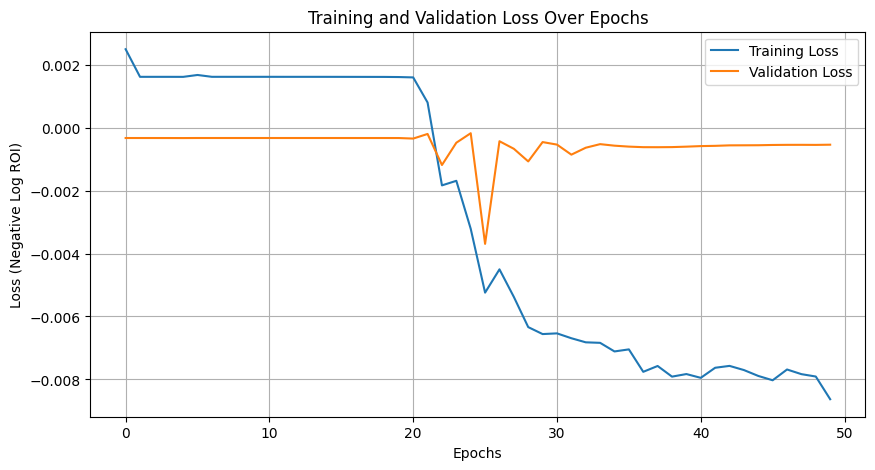


Evaluating model on the test set...
Evaluation complete.


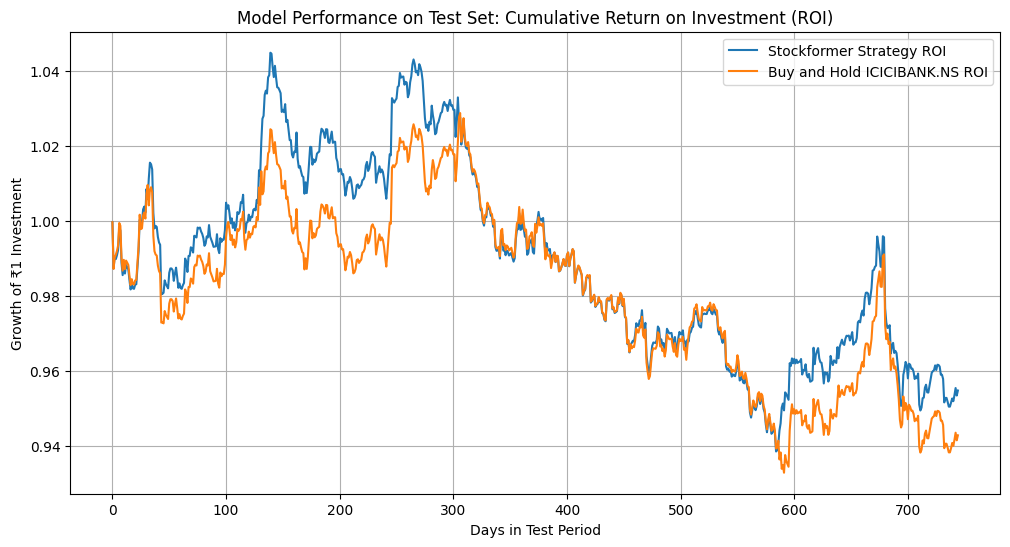

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import time

# --- STEP 6: MODEL-SPECIFIC CONFIGURATION ---
# These hyperparameters are crucial for the model's performance.
# They are good starting points based on common practices for such models.
SEQUENCE_LENGTH = 120  # Use the last 60 days of data to predict the next day.
NUM_FEATURES = len(TICKERS) # The number of stocks we are using as input.
EMBEDDING_DIM = 128   # The dimension of the feature space after the CNN embedding.
NUM_HEADS = 8         # Number of attention heads in the Transformer.
NUM_LAYERS = 3        # Number of Transformer encoder layers.
DROPOUT = 0.1         # Dropout rate for regularization.
LEARNING_RATE = 0.0001
EPOCHS = 50
BATCH_SIZE = 32

print("\n--- Model & Training Configuration ---")
print(f"Target Stock for Prediction: {target_stock}")
print(f"Input Features (Tickers): {TICKERS}")
print(f"Sequence Length (Lookback): {SEQUENCE_LENGTH} days")
print("------------------------------------")


# --- STEP 7: DATA PREPARATION FOR THE MODEL ---
def create_sequences(data, target_stock, sequence_length):
    """
    Creates input sequences (X) and target labels (y) for the time-series model.
    """
    print("\nCreating training sequences...")
    X, y = [], []
    # The features are all stock returns
    features = data.values
    # The target is the return of our chosen stock
    target = data[target_stock].values

    for i in range(len(data) - sequence_length):
        # Input: a sequence of length `sequence_length` with all features
        X.append(features[i:(i + sequence_length)])
        # Target: the return of the target stock on the next day
        y.append(target[i + sequence_length])

    print(f"Generated {len(X)} sequences.")
    return np.array(X), np.array(y)

# --- STEP 8: THE STOCKFORMER MODEL ARCHITECTURE ---
class PositionalEncoding(nn.Module):
    """
    Injects position information into the input embeddings. This is crucial for
    the Transformer as it does not have an inherent sense of sequence order.
    """
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:x.size(0), :]

class Stockformer(nn.Module):
    """
    The main Stockformer model architecture, combining a 1D-CNN embedding
    layer with a standard Transformer Encoder.
    """
    def __init__(self, num_features, embedding_dim, num_heads, num_layers, dropout):
        super(Stockformer, self).__init__()

        # V-A2: 1D-CNN Based Token Embedding
        # This layer acts as the feature extractor, learning temporal patterns.
        self.embedding = nn.Conv1d(
            in_channels=num_features,
            out_channels=embedding_dim,
            kernel_size=3,
            padding=1
        )
        self.relu = nn.ReLU()

        # Positional Encoding
        self.pos_encoder = PositionalEncoding(embedding_dim)

        # Standard Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dropout=dropout,
            batch_first=True  # Important: ensures input format is (batch, seq, feature)
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # The final output layer
        self.output_layer = nn.Linear(embedding_dim, 1)

    def forward(self, src):
        # src shape: (batch_size, sequence_length, num_features)

        # The CNN layer expects (batch_size, num_features, sequence_length)
        src = src.permute(0, 2, 1)
        embedded = self.relu(self.embedding(src))

        # Switch back to (batch_size, sequence_length, embedding_dim)
        embedded = embedded.permute(0, 2, 1)

        # Add positional encoding
        # The pos_encoder expects (sequence_length, batch_size, embedding_dim)
        positioned = embedded.permute(1, 0, 2)
        positioned = self.pos_encoder(positioned)
        positioned = positioned.permute(1, 0, 2)

        # Pass through the Transformer Encoder
        transformer_output = self.transformer_encoder(positioned)

        # We use the output of the last time step for prediction
        last_step_output = transformer_output[:, -1, :]

        # Final prediction
        output = self.output_layer(last_step_output)
        return output

# --- STEP 9: CUSTOM LOSS FUNCTION ---
def stock_tanh_loss(predictions, targets):
    """
    VI-A4: Stock Tanh Loss Function.
    This loss function calculates the negative of the log return on investment.
    Minimizing this loss is equivalent to maximizing the investment return.
    """
    # The model's raw output is the prediction. We pass it through tanh to
    # decide the percentage of our portfolio to invest (long or short).
    investment_decision = torch.tanh(predictions.squeeze())

    # Calculate the profit/loss for each day based on our decision and the actual return
    daily_log_returns = investment_decision * targets

    # We want to maximize the sum of log returns. To make it a loss function
    # that we need to minimize, we take the negative of the sum.
    # Adding a small constant for stability if all returns are zero.
    loss = -torch.sum(daily_log_returns) + 1e-8

    return loss

# --- STEP 10: TRAINING & EVALUATION ---
def train_and_evaluate(model, train_loader, val_loader):
    """
    The main training loop for the model.
    """
    # Set device to GPU if available, else CPU
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\nTraining on device: {device}")
    model.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    # VI-B3: Reduce Learning Rate On Plateau Scheduler
    # *** FIX: Removed the 'verbose' argument for broader compatibility ***
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', factor=0.5, patience=3)

    history = {'train_loss': [], 'val_loss': []}

    start_time = time.time()
    for epoch in range(EPOCHS):
        model.train()
        total_train_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = stock_tanh_loss(predictions, y_batch)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_loader)
        history['train_loss'].append(avg_train_loss)

        # Validation
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                predictions = model(X_batch)
                loss = stock_tanh_loss(predictions, y_batch)
                total_val_loss += loss.item()

        avg_val_loss = total_val_loss / len(val_loader)
        history['val_loss'].append(avg_val_loss)

        print(f"Epoch {epoch+1}/{EPOCHS} -> Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

        scheduler.step(avg_val_loss)

    end_time = time.time()
    print(f"\nTraining finished in {end_time - start_time:.2f} seconds.")
    return model, history

def plot_training_history(history):
    plt.figure(figsize=(10, 5))
    plt.plot(history['train_loss'], label='Training Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (Negative Log ROI)')
    plt.legend()
    plt.grid(True)
    plt.show()

def evaluate_on_test_set(model, test_loader):
    """
    Evaluates the model on the unseen test set and plots the cumulative return.
    """
    print("\nEvaluating model on the test set...")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()

    all_targets = []
    all_decisions = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            predictions = model(X_batch)

            # Handle cases where the batch size is 1, which would cause squeeze() to remove the dimension
            if predictions.squeeze().dim() == 0:
                decisions = torch.tanh(predictions.squeeze().unsqueeze(0)).cpu().numpy()
            else:
                decisions = torch.tanh(predictions.squeeze()).cpu().numpy()

            all_decisions.extend(decisions)
            all_targets.extend(y_batch.numpy())

    all_targets = np.array(all_targets)
    all_decisions = np.array(all_decisions)

    # Calculate the daily log returns based on the model's strategy
    strategy_log_returns = all_decisions * all_targets

    # Calculate cumulative returns
    cumulative_strategy_return = np.exp(np.cumsum(strategy_log_returns))

    # Compare with a simple "buy and hold" strategy for the target stock
    buy_and_hold_return = np.exp(np.cumsum(all_targets))

    print("Evaluation complete.")

    # Plotting the results
    plt.figure(figsize=(12, 6))
    plt.plot(cumulative_strategy_return, label='Stockformer Strategy ROI')
    plt.plot(buy_and_hold_return, label=f'Buy and Hold {target_stock} ROI')
    plt.title('Model Performance on Test Set: Cumulative Return on Investment (ROI)')
    plt.xlabel('Days in Test Period')
    plt.ylabel('Growth of ₹1 Investment')
    plt.legend()
    plt.grid(True)
    plt.show()

# --- MAIN EXECUTION (Continued) ---
if __name__ == "__main__":
    # This block assumes the variables `processed_data` and `target_stock`
    # are available from the previous script run in the same session.

    # 7. Create sequences
    X, y = create_sequences(processed_data, target_stock, SEQUENCE_LENGTH)

    # 8. Scale the features and split the data
    # Note: We only scale the input features (X), not the target (y),
    # because our loss function works directly with the log returns.
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X.reshape(-1, NUM_FEATURES)).reshape(X.shape)

    X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, shuffle=False)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=False)

    # Convert to PyTorch Tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)
    y_val = torch.tensor(y_val, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_test = torch.tensor(y_test, dtype=torch.float32)

    # Create DataLoaders
    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_dataset = TensorDataset(X_val, y_val)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_dataset = TensorDataset(X_test, y_test)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    print(f"\nData split complete:")
    print(f"Training set size: {len(X_train)}")
    print(f"Validation set size: {len(X_val)}")
    print(f"Test set size: {len(X_test)}")

    # 9. Instantiate and train the model
    stockformer_model = Stockformer(
        num_features=NUM_FEATURES,
        embedding_dim=EMBEDDING_DIM,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT
    )

    trained_model, history = train_and_evaluate(stockformer_model, train_loader, val_loader)

    # 10. Visualize training and evaluate on the test set
    plot_training_history(history)
    evaluate_on_test_set(trained_model, test_loader)

